# Figure S7: PyGEM-WBM Glacier-Water Paper
The following notebook includes the code that is used to create regional time series of glacier-sourced water in populated basins, people supported, and crops supported that were used to create Figure S7 in the accompanying study.

In [1]:
import os

import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, FixedLocator, LogLocator, NullFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from shapely.geometry import Point
import xarray as xr

In [2]:
main_directory = os.getcwd()

ssps = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
gcm_names = ['BCC-CSM2-MR', 'CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-f3-L', 
             'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'MPI-ESM1-2-HR', 'MRI-ESM2-0', 'NorESM2-MM']

# Plotting details
ssp_name_dict = {'ssp126':'SSP1-2.6',
                 'ssp245':'SSP2-4.5',
                 'ssp370':'SSP3-7.0',
                 'ssp585':'SSP5-8.5',
                }

ssp_colordict = {'ssp119':'#081d58', 'ssp126':'#1d91c0', 'ssp245':'#7fcdbb', 'ssp370':'#F47A20', 'ssp585':'#ED2024'}

paper_fig_fp = 'figures_paper/'
if not os.path.exists(paper_fig_fp):
    os.makedirs(paper_fig_fp)

## Glacier Runoff Data

### RGI regions with considerable populations

In [3]:
pop_fp = 'wbm_data/population_gridded/'
pop_fn = 'historical_population_per_grid.nc'

ds_pop = xr.open_dataset(pop_fp + pop_fn)
pop = ds_pop['population']
         
# Convert to dataframe
pop_df = pop[0,:,:].to_dataframe().reset_index()

# Add geometry
pop_df['geometry'] = gpd.points_from_xy(pop_df.longitude.values, pop_df.latitude.values)
            
# Load regions
cont_fp = 'ipcc_regions/'
cont_fn = 'IPCC-WGII-continental-regions.geojson'
cont_gdf = gpd.read_file(cont_fp + cont_fn)

# Convert to geodataframe
pop_gdf = gpd.GeoDataFrame(pop_df, crs=cont_gdf.crs)

# Spatial join
# - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
# - 'intersects' tells to join any where it intersects which is good for point vs vector data
pop_gdf_wconts = gpd.sjoin(pop_gdf, cont_gdf, how='inner', predicate='intersects')

# Load RGI regions
rgi_reg_fp = 'rgi_regions/'
rgi_reg_fn = '00_rgi60_O1Regions.shp'
rgi_gdf = gpd.read_file(rgi_reg_fp + rgi_reg_fn)
rgi_gdf = rgi_gdf.to_crs(cont_gdf.crs)
pop_gdf_wconts.drop(columns=['index_right'], inplace=True)
pop_gdf_wconts_wrgi = gpd.sjoin(pop_gdf_wconts, rgi_gdf, how='inner', predicate='intersects')

# Only include RGI regions in the glacier runoff calculations that have at least a certain number of people 
rgi_no_2include = []
min_rgi_pop = 10000 # min people must live in the RGI region to be included 
for rgi_no in range(1,20):
    rgi_pop = pop_gdf_wconts_wrgi.loc[pop_gdf_wconts_wrgi['RGI_CODE'] == rgi_no, 'population'].sum()
    if rgi_pop>min_rgi_pop:
        print(rgi_no, rgi_pop)
        rgi_no_2include.append(rgi_no)

rgi_no_2include.remove(5) # Remove Greenland

1 819462.75
2 44914876.0
4 18403.693
5 18594.873
6 430920.7
8 24699386.0
10 237554430.0
11 245690000.0
12 174557950.0
13 81001784.0
14 211536500.0
15 315678980.0
16 571597400.0
17 24997028.0
18 3704060.0


### Glacier runoff in regions with considerable populations

### Historical data

In [4]:
# ----- Code to create the historical dataset (processed 6/22/2026) and no longer needed -----
# wbm_data_fp = 'wbm_data/glMelt/historical/'
# yrs_str = [str(x) for x in range(1980,2016)]

# ds2merge = []
# for yr_str in yrs_str:
#     wbm_fn = 'wbm_' + yr_str + '.nc'
#     ds_wbm = xr.open_dataset(wbm_data_fp + wbm_fn)
#     ds2merge.append(ds_wbm)

# ds_all = xr.concat(ds2merge, dim="time")

# # drop time and just provide year
# ds_all = ds_all.assign_coords(year=("time", ds_all.time.dt.year.values)).swap_dims({"time": "year"}).drop_vars("time")

# ds_all.to_netcdf('wbm_data/glMelt/historical_v4-glMelt.nc')

In [5]:
rois = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

glac_runoff_fp = 'wbm_data/glMelt/'
glac_runoff_fp_processed = 'processed_data/glMelt/'

glac_runoff_cont_fn = 'historical_continents-glacier_runoff.csv'

if not os.path.exists(glac_runoff_fp_processed + glac_runoff_cont_fn):
            
    # Glacier runoff (i.e., glacier-sourced water)
    glac_runoff_fn = 'historical_v4-glMelt.nc'
    ds_glac = xr.open_dataset(glac_runoff_fp + glac_runoff_fn)

    glRunoff = ds_glac['glMelt']
    
    glRunoff_df_allyears = None
    for nyear, year in enumerate(np.arange(1980,2016)):
    
        if nyear%10==0:
            print('  ', year)
            
        # Convert to dataframe
        glRunoff_df = glRunoff[nyear,:,:].to_dataframe().reset_index()

        # Rename columns
        glRunoff_df = glRunoff_df.rename(columns={'glMelt':str(year)})
    
        if glRunoff_df_allyears is None:
            glRunoff_df_allyears = glRunoff_df
        else:
            glRunoff_df_allyears = glRunoff_df_allyears.join(glRunoff_df[str(year)])
    
    # Add geometry
    glRunoff_df_allyears['geometry'] = gpd.points_from_xy(glRunoff_df_allyears.lon.values, 
                                                          glRunoff_df_allyears.lat.values)
    
    # Load regions
    cont_gdf = gpd.read_file(cont_fp + cont_fn)
    
    # Convert to geodataframe
    glRunoff_gdf = gpd.GeoDataFrame(glRunoff_df_allyears, crs=cont_gdf.crs)
    
    # Spatial join
    # - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
    # - 'intersects' tells to join any where it intersects which is good for point vs vector data
    glRunoff_gdf_wconts = gpd.sjoin(glRunoff_gdf, cont_gdf, how='inner', predicate='intersects')

    # Load RGI regions
    rgi_gdf = gpd.read_file(rgi_reg_fp + rgi_reg_fn)
    rgi_gdf = rgi_gdf.to_crs(cont_gdf.crs)
    glRunoff_gdf_wconts.drop(columns=['index_right'], inplace=True)
    glRunoff_gdf_wconts_wrgi = gpd.sjoin(glRunoff_gdf_wconts, rgi_gdf, how='inner', predicate='intersects')

    # PROCESS ROIs
    yr_cns = [str(x) for x in range(1980,2016)]
    data_rois = pd.DataFrame(np.zeros((len(rois), len(yr_cns)+1)), columns=['Name'] + yr_cns)
    data_rois['Name'] = data_rois['Name'].astype(str)
    data_rois['Name'] = rois
    for nroi, roi in enumerate(rois):

        # Subset by continent
        if roi not in ['Global']:
            data_ssp = glRunoff_gdf_wconts_wrgi[glRunoff_gdf_wconts_wrgi['Name'] == roi]
        else:
            data_ssp = glRunoff_gdf_wconts_wrgi
    
        # Subset by RGI regions with populations
        data_ssp = data_ssp[data_ssp['RGI_CODE'].isin(rgi_no_2include)]
            
        data_rois.loc[nroi,yr_cns] = data_ssp[yr_cns].sum(0)
    
    # export the aggregated data
    if not os.path.exists(glac_runoff_fp_processed):
        os.makedirs(glac_runoff_fp_processed)
    data_rois.to_csv(glac_runoff_fp_processed + glac_runoff_cont_fn, index=False)

### Future data

In [6]:
rois = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']

glac_runoff_fp = 'wbm_data/glMelt/'
glac_runoff_fp_gcms = 'processed_data/glMelt/individual_gcms/'

for nssp, ssp in enumerate(ssps[0:1]):
    for ngcm, gcm_name in enumerate(gcm_names[0:1]):

        glac_runoff_cont_fn = gcm_name + '-' + ssp + '_continents-glacier_runoff.csv'

        if not os.path.exists(glac_runoff_fp_gcms + glac_runoff_cont_fn):
            
            print(ssp, gcm_name)
            
            # Glacier runoff (i.e., glacier-sourced water)
            glac_runoff_fn = 'wbm_' + gcm_name + '_' + ssp + '_2000_2099_v4-glMelt.nc'
            ds_glac = xr.open_dataset(glac_runoff_fp + glac_runoff_fn)

            glRunoff = ds_glac['glMelt']
            
            glRunoff_df_allyears = None
            for nyear, year in enumerate(np.arange(2016,2100)):
            # for nyear, year in enumerate([2016]):
            
                if nyear%10==0:
                    print('  ', year)
                    
                # Convert to dataframe
                glRunoff_df = glRunoff[nyear,:,:].to_dataframe().reset_index()

                # Rename columns
                glRunoff_df = glRunoff_df.rename(columns={'glMelt':str(year)})
            
                if glRunoff_df_allyears is None:
                    glRunoff_df_allyears = glRunoff_df
                else:
                    glRunoff_df_allyears = glRunoff_df_allyears.join(glRunoff_df[str(year)])
            
            # Add geometry
            glRunoff_df_allyears['geometry'] = gpd.points_from_xy(glRunoff_df_allyears.lon.values, 
                                                                  glRunoff_df_allyears.lat.values)
            
            # Load regions
            cont_gdf = gpd.read_file(cont_fp + cont_fn)
            
            # Convert to geodataframe
            glRunoff_gdf = gpd.GeoDataFrame(glRunoff_df_allyears, crs=cont_gdf.crs)
            
            # Spatial join
            # - 'inner' tells it to use keys (column names) from both dataframes and retain those on the left
            # - 'intersects' tells to join any where it intersects which is good for point vs vector data
            glRunoff_gdf_wconts = gpd.sjoin(glRunoff_gdf, cont_gdf, how='inner', predicate='intersects')

            # Load RGI regions
            rgi_gdf = gpd.read_file(rgi_reg_fp + rgi_reg_fn)
            rgi_gdf = rgi_gdf.to_crs(cont_gdf.crs)
            glRunoff_gdf_wconts.drop(columns=['index_right'], inplace=True)
            glRunoff_gdf_wconts_wrgi = gpd.sjoin(glRunoff_gdf_wconts, rgi_gdf, how='inner', predicate='intersects')
    
            # PROCESS ROIs
            yr_cns = [str(x) for x in range(2016,2100)]
            data_rois = pd.DataFrame(np.zeros((len(rois), len(yr_cns)+1)), columns=['Name'] + yr_cns)
            data_rois['Name'] = data_rois['Name'].astype(str)
            data_rois['Name'] = rois
            for nroi, roi in enumerate(rois):

                # Subset by continent
                if roi not in ['Global']:
                    data_ssp = glRunoff_gdf_wconts_wrgi[glRunoff_gdf_wconts_wrgi['Name'] == roi]
                else:
                    data_ssp = glRunoff_gdf_wconts_wrgi
            
                # Subset by RGI regions with populations
                data_ssp = data_ssp[data_ssp['RGI_CODE'].isin(rgi_no_2include)]
            
                
                data_rois.loc[nroi,yr_cns] = data_ssp[yr_cns].sum(0)
            
            # export the aggregated data
            if not os.path.exists(glac_runoff_fp_gcms):
                os.makedirs(glac_runoff_fp_gcms)
            data_rois.to_csv(glac_runoff_fp_gcms + glac_runoff_cont_fn, index=False)

#### Multi-GCM median

In [7]:
yr_cns = [str(x) for x in np.arange(2016,2100)]

glac_runoff_fp_med = 'processed_data/glMelt/'

for ssp in ssps:

    glac_runoff_cont_fn_med = ssp + '_continents-glacier_runoff-med.csv'
    
    if not os.path.exists(glac_runoff_fp_med + glac_runoff_cont_fn_med):

        for ngcm, gcm_name in enumerate(gcm_names):
        
            glac_runoff_cont_fn = gcm_name + '-' + ssp + '_continents-glacier_runoff.csv'
    
            glRunoff_df = pd.read_csv(glac_runoff_fp_gcms + glac_runoff_cont_fn)
        
            if ngcm == 0:
                glRunoff_all = glRunoff_df[yr_cns].values[np.newaxis,:,:]
            else:
                glRunoff_all = np.concatenate((glRunoff_all, glRunoff_df[yr_cns].values[np.newaxis,:,:]), axis=0)
        
        glRunoff_med = np.median(glRunoff_all, axis=0)
    
        glRunoff_med_df = pd.DataFrame(np.zeros((len(rois), len(yr_cns)+1)), columns=['Name'] + yr_cns)
        glRunoff_med_df['Name'] = glRunoff_med_df['Name'].astype(str)
        glRunoff_med_df['Name'] = rois
        glRunoff_med_df.loc[:,yr_cns] = glRunoff_med
    
        glRunoff_med_df.to_csv(glac_runoff_fp_med + glac_runoff_cont_fn_med, index=False)

# Glacier Runoff, Population supported, Crop Production

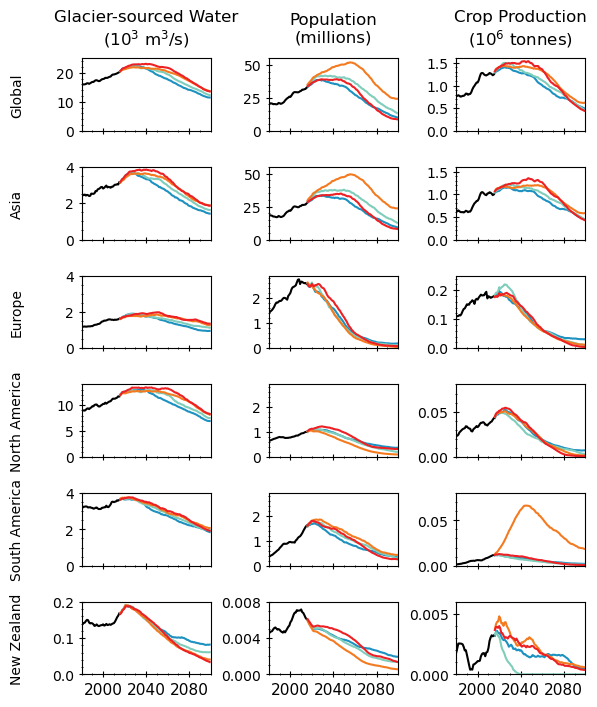

In [8]:
ssps2plot = ['ssp126', 'ssp245', 'ssp370', 'ssp585']

rois2plot = ['Global', 'Asia', 'Europe', 'North America', 'Central and South America', 'Australasia']
# rois2plot = ['Global']
rois_labeldict = {'Global':'Global', 
                  'Asia':'Asia', 
                  'Europe':'Europe', 
                  'North America':'North America', 
                  'Central and South America':'South America', 
                  'Australasia':'New Zealand'}

fig, ax = plt.subplots(nrows=6, ncols=3, figsize=(6.5, 8), gridspec_kw={'hspace': 0.5, 'wspace':0.45}, sharex=True)

yrs_hist = range(1980,2016)
yrs = range(2016,2100)

yr_cns_hist = [str(x) for x in yrs_hist]
yr_cns = [str(x) for x in yrs]

for ncol in range(0,3):

    for ssp in ssps2plot:

         # ----- GLACIER RUNOFF (FIRST COLUMN) -----
        if ncol == 0:

            # Historical data
            glac_runoff_cont_fp = 'processed_data/glMelt/'
            glac_runoff_cont_fn_hist = 'historical_continents-glacier_runoff.csv'
            df_hist = pd.read_csv(glac_runoff_cont_fp + glac_runoff_cont_fn_hist)
        
            # Future data
            glac_runoff_cont_fn_ssp = ssp + '_continents-glacier_runoff-med.csv'
            df_ssp = pd.read_csv(glac_runoff_cont_fp + glac_runoff_cont_fn_ssp)
            
            # Concatenate for moving average and plot each region
            for nroi, roi in enumerate(rois2plot):
                data_hist = df_hist.loc[nroi,yr_cns_hist].values.astype(np.float64)
                data_ssp = df_ssp.loc[nroi,yr_cns].values.astype(np.float64)

                data_hist_wssp = np.concatenate((data_hist, data_ssp)) / 1e3
                data_hist_wssp_movingavg = uniform_filter(data_hist_wssp, size=(11), mode='nearest')

                # Historical plot
                if ssp in ['ssp245']:
                    ax[nroi,ncol].plot(yrs_hist, data_hist_wssp_movingavg[0:data_hist.shape[0]], color='k')
    
                # Future plots
                ax[nroi,ncol].plot(yrs, data_hist_wssp_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])

                # ----- LABELS/FORMATING -----
                ax[nroi,ncol].set_xlim(1980, 2100)
                ax[nroi,ncol].yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
                ax[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))  # Major ticks every 25
                ax[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))    # Minor ticks every 5
                ax[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
                ax[nroi,ncol].tick_params(axis='both', which='minor', direction='inout', length=2)
                ax[nroi,ncol].tick_params(axis='x', labelsize=11)

                if nroi == 0:
                    ax[nroi,ncol].set_title('Glacier-sourced Water\n(10$^{3}$ m$^{3}$/s)', pad=10, size=12)

                if roi in ['Global']:
                    ax[nroi,ncol].set_ylim(0, 25)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(10)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(2))
                elif roi in ['Asia', 'Europe', 'Central and South America']:
                    ax[nroi,ncol].set_ylim(0, 4)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(2)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.5))
                elif roi in ['North America']:
                    ax[nroi,ncol].set_ylim(0, 14)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(5)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(1))
                elif roi in ['Australasia']:
                    ax[nroi,ncol].set_ylim(0, 0.2)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(0.1)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.02))

        # ----- POPULATIONS SUPPORTED (SECOND COLUMN) -----
        if ncol == 1:

            # Historical data
            pop_pg_fp = 'processed_data/domestic_pg_people/'
            pop_pg_fn_hist = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
            df_hist = pd.read_csv(pop_pg_fp + pop_pg_fn_hist)
        
            # Future data
            pop_pg_fn_ssp = ssp + '_global_continents_people_pg-byfrac-byelev_med.csv'
            df_ssp = pd.read_csv(pop_pg_fp + pop_pg_fn_ssp)
            
            # Concatenate for moving average and plot each region
            for nroi, roi in enumerate(rois2plot):
                data_hist = df_hist.loc[(df_hist['Name'] == roi) & 
                                        (df_hist['elev_threshold'] == 0) & 
                                        (df_hist['frac'] == 0.01), yr_cns_hist].values[0,:]
                data_ssp = df_ssp.loc[(df_ssp['Name'] == roi) & 
                                      (df_ssp['elev_threshold'] == 0) & 
                                      (df_ssp['frac'] == 0.01), yr_cns].values[0,:]

                data_hist_wssp = np.concatenate((data_hist, data_ssp)) / 1e6
                data_hist_wssp_movingavg = uniform_filter(data_hist_wssp, size=(11), mode='nearest')

                # Historical plot
                if ssp in ['ssp245']:
                    ax[nroi,ncol].plot(yrs_hist, data_hist_wssp_movingavg[0:data_hist.shape[0]], color='k')
    
                # Future plots
                ax[nroi,ncol].plot(yrs, data_hist_wssp_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])

                # ----- LABELS/FORMATING -----
                ax[nroi,ncol].set_xlim(1980, 2100)
                ax[nroi,ncol].yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
                ax[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))  # Major ticks every 25
                ax[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))    # Minor ticks every 5
                ax[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
                ax[nroi,ncol].tick_params(axis='both', which='minor', direction='inout', length=2)
                ax[nroi,ncol].tick_params(axis='x', labelsize=11)

                if nroi == 0:
                    ax[nroi,ncol].set_title('Population\n(millions)', pad=12, size=12)

                if roi in ['Global', 'Asia']:
                    ax[nroi,ncol].set_ylim(0, 55)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(25)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(5))
                elif roi in ['Europe', 'Central and South America', 'North America']:
                    ax[nroi,ncol].set_ylim(0, 2.9)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(1)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.2))
                elif roi in ['Australasia']:
                    ax[nroi,ncol].set_ylim(0, 0.008)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(0.004)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.001))

        # ----- CROP PRODUCTION SUPPORTED (THIRD COLUMN) -----
        if ncol == 2:

            # Historical data
            irrProd_fp = 'processed_data/IrrProduction_pg/'
            irrProd_fn_hist = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
            df_hist = pd.read_csv(irrProd_fp + irrProd_fn_hist)
        
            # Future data
            irrProd_fn_ssp = ssp + '_continents_irrProduction_pg_kg-byfrac-byelev_med.csv'
            df_ssp = pd.read_csv(irrProd_fp + irrProd_fn_ssp)
            
            # Concatenate for moving average and plot each region
            for nroi, roi in enumerate(rois2plot):
                data_hist = df_hist.loc[(df_hist['Name'] == roi) & 
                                        (df_hist['elev_threshold'] == 0) & 
                                        (df_hist['frac'] == 0.01), yr_cns_hist].values[0,:]
                data_ssp = df_ssp.loc[(df_ssp['Name'] == roi) & 
                                      (df_ssp['elev_threshold'] == 0) & 
                                      (df_ssp['frac'] == 0.01), yr_cns].values[0,:]

                data_hist_wssp = np.concatenate((data_hist, data_ssp)) / 1e9
                data_hist_wssp_movingavg = uniform_filter(data_hist_wssp, size=(11), mode='nearest')

                # Historical plot
                if ssp in ['ssp245']:
                    ax[nroi,2].plot(yrs_hist, data_hist_wssp_movingavg[0:data_hist.shape[0]], color='k')
    
                # Future plots
                ax[nroi,2].plot(yrs, data_hist_wssp_movingavg[data_hist.shape[0]:], color=ssp_colordict[ssp])

                # ----- LABELS/FORMATING -----
                ax[nroi,ncol].set_xlim(1980, 2100)
                ax[nroi,ncol].yaxis.set_minor_formatter(NullFormatter())  # Hide minor tick labels
                ax[nroi,ncol].xaxis.set_major_locator(MultipleLocator(40))  # Major ticks every 25
                ax[nroi,ncol].xaxis.set_minor_locator(MultipleLocator(10))    # Minor ticks every 5
                ax[nroi,ncol].tick_params(axis='both', which='major', direction='inout', length=4)
                ax[nroi,ncol].tick_params(axis='both', which='minor', direction='inout', length=2)
                ax[nroi,ncol].tick_params(axis='x', labelsize=11)

                if nroi == 0:
                    ax[nroi,ncol].set_title('Crop Production\n(10$^{6}$ tonnes)', pad=10, size=12)

                if roi in ['Global', 'Asia']:
                    ax[nroi,ncol].set_ylim(0, 1.6)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(0.5)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.1))
                elif roi in ['Europe']:
                    ax[nroi,ncol].set_ylim(0, 0.25)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(0.1)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.02))
                elif roi in ['Central and South America', 'North America']:
                    ax[nroi,ncol].set_ylim(0, 0.08)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(0.05)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.01))
                elif roi in ['Australasia']:
                    ax[nroi,ncol].set_ylim(0, 0.006)
                    ax[nroi,ncol].yaxis.set_major_locator(MultipleLocator(0.005)) 
                    ax[nroi,ncol].yaxis.set_minor_locator(MultipleLocator(0.001))

# Row labels on left side
for nroi, roi in enumerate(rois2plot):

    if roi == 'Australasia':
        label = 'New Zealand'
    elif roi == 'Central and South America':
        label = 'South America'
    else:
        label = roi

    ax[nroi,0].text(-0.5, 0.5, label, rotation=90, transform=ax[nroi,0].transAxes, va='center', ha='center', fontsize=10)


fig.savefig(paper_fig_fp + 'figS7_continent_glRunoff_Population_Crops_timeseries.png', bbox_inches='tight', dpi=300)
plt.show()